# Customer Transaction Prediction
**Goal:** Predict which bank customers will make a transaction in the future (target: 0 = no, 1 = yes).

**Tasks:** 1) Data analysis report, 2) Predictive model, 3) Model comparison report, 4) Challenges report

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv(r"D:\DataMites_documents\1st Cpaston\PRCP-1003-CustTransPred\Data\train(1).csv")
print("Shape:", df.shape)


Shape: (200000, 202)


**Observation:** The dataset has X rows and 202 columns: `ID_code` (identifier), `target` (what we predict) and 200 anonymized features (var_0 to var_199).

# Task 1: Data Analysis Report

In [4]:
df.info(verbose=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


In [5]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


**Observation:** There are no missing values and no duplicates, and all features are numeric. So no cleaning or encoding is needed.

target
0    179902
1     20098
Name: count, dtype: int64
target
0    89.951
1    10.049
Name: proportion, dtype: float64


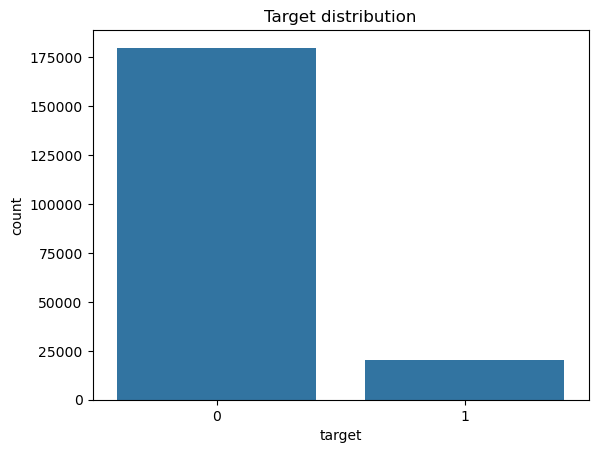

In [6]:
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True) * 100)

sns.countplot(x="target", data=df)
plt.title("Target distribution")
plt.show()

**Observation:** About 90% of customers are class 0 and only about 10% are class 1, so the data is **imbalanced**.
**Impact:** Accuracy is misleading (predicting all 0 gives ~90%). I will use ROC-AUC, Precision, Recall and F1.

In [7]:
# Feature statistics
df.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
target,200000.0,0.100490,0.300653,0.0000,0.000000,0.00000,0.000000,1.0000
var_0,200000.0,10.679914,3.040051,0.4084,8.453850,10.52475,12.758200,20.3150
var_1,200000.0,-1.627622,4.050044,-15.0434,-4.740025,-1.60805,1.358625,10.3768
var_2,200000.0,10.715192,2.640894,2.1171,8.722475,10.58000,12.516700,19.3530
var_3,200000.0,6.796529,2.043319,-0.0402,5.254075,6.82500,8.324100,13.1883
var_4,200000.0,11.078333,1.623150,5.0748,9.883175,11.10825,12.261125,16.6714
var_5,200000.0,-5.065317,7.863267,-32.5626,-11.200350,-4.83315,0.924800,17.2516
var_6,200000.0,5.408949,0.866607,2.3473,4.767700,5.38510,6.003000,8.4477
var_7,200000.0,16.545850,3.418076,5.3497,13.943800,16.45680,19.102900,27.6918
var_8,200000.0,0.284162,3.332634,-10.5055,-2.317800,0.39370,2.937900,10.1513


**Observation:**
- All 200,000 rows are filled for every column (count = 200000).
- The mean of `target` is 0.1005, so about 10% of customers are class 1 and about 90% are class 0 (imbalanced data).
- Feature scales differ a lot: for example, `var_6` has a standard deviation of 0.87 and a range of 2.3 to 8.4, while `var_5` has a standard deviation of 7.86 and a range of -32.6 to 17.3.
- For each feature the mean and median are close, so the distributions look roughly symmetric.

**Decision:** I will scale the features with `StandardScaler` for Logistic Regression. Tree-based models do not need scaling.

In [11]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outlier_pct = ((X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)).mean() * 100

print("Average % of outliers per feature:", round(outlier_pct.mean(), 2))
print("Highest % of outliers in one feature:", round(outlier_pct.max(), 2))

Average % of outliers per feature: 0.07
Highest % of outliers in one feature: 0.75


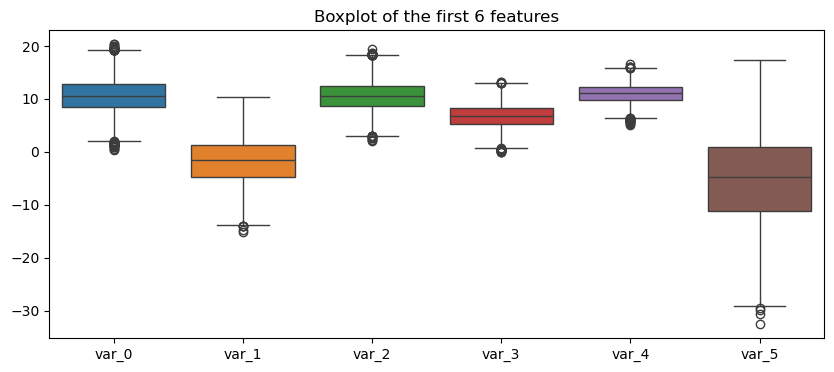

In [12]:
#Outliers
plt.figure(figsize=(10, 4))
sns.boxplot(data=df.iloc[:, 2:8])
plt.title("Boxplot of the first 6 features")
plt.show()

**Observation:**
- The boxes are compact and the medians are near the center, so the features are roughly symmetric.
- A small number of outliers appear at the extreme ends, for example `var_5` and `var_1` at the low end and `var_0` at both ends. They are very few compared with 200,000 rows.
- `var_5` has the widest spread and `var_4` the narrowest.

**Decision:** These values look like natural variation, not data errors, so I keep them. Tree-based models such as Random Forest and LightGBM are not sensitive to outliers.

In [13]:
#Correlation
X = df.drop(["ID_code", "target"], axis=1)
y = df["target"]

corr = X.corr().abs().values.copy()
np.fill_diagonal(corr, 0)
print("Highest correlation between two features:", round(corr.max(), 4))

target_corr = X.corrwith(y).abs().sort_values(ascending=False)
print("\nTop 5 features correlated with target:")
print(target_corr.head(5))

Highest correlation between two features: 0.0098

Top 5 features correlated with target:
var_81     0.080917
var_139    0.074080
var_12     0.069489
var_6      0.066731
var_110    0.064275
dtype: float64


**Observation:**
- The highest correlation between any two features is only **0.0098**, so the features are almost completely independent. There is no multicollinearity, and no feature needs to be dropped for that reason.
- The strongest correlation with the target is only **0.081** (`var_81`), followed by `var_139` (0.074), `var_12` (0.069), `var_6` (0.067) and `var_110` (0.064). Every feature is therefore only weakly related to the target.

**Inference:** No single feature can predict the target. The predictive signal is weak and spread across many features, so I need models that combine many features (tree-based models such as Random Forest and LightGBM) rather than relying on one or two variables.

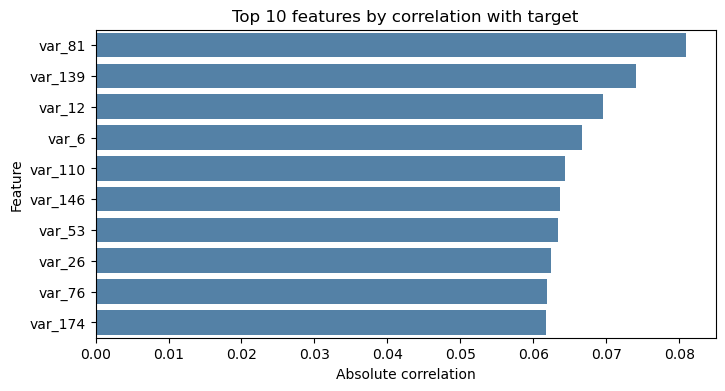

In [14]:
plt.figure(figsize=(8, 4))
sns.barplot(x=target_corr.head(10).values, y=target_corr.head(10).index, color="steelblue")
plt.title("Top 10 features by correlation with target")
plt.xlabel("Absolute correlation")
plt.ylabel("Feature")
plt.show()

**Observation:**
- The strongest feature is `var_81` (about 0.081), followed by `var_139` (0.074), `var_12` (0.069) and `var_6` (0.067).
- From the 5th feature onward the values are almost equal (about 0.062 to 0.064), so there is no single standout feature.
- Even the best feature is below 0.09, which is a very weak relationship.

**Inference:** The predictive signal is spread thinly across many features. This supports using models that combine many features, such as Random Forest and LightGBM.

## Summary of Task 1: Data Analysis

| Check | Finding | What it means for modeling |
|---|---|---|
| Size | 200,000 rows, 202 columns (200 features + `ID_code` + `target`) | Large dataset |
| Missing values / duplicates | (write your result from the notebook) | No cleaning needed if both are 0 |
| Target balance | About 10% class 1 and 90% class 0 | Imbalanced: use class weights, stratified split, ROC-AUC |
| Feature scales | Very different (for example `var_5` std 7.86 vs `var_6` std 0.87) | Scale for Logistic Regression |
| Outliers | Few, look natural | Keep them |
| Correlation between features | Highest is 0.0098 | Features are independent, no multicollinearity |
| Correlation with target | Highest is 0.081 (`var_81`) | Weak signal, use tree-based models |

# Task 2: Predictive Model

**Goal:** Build a model that predicts whether a customer will make a transaction (1) or not (0).

**Plan:**
1. Split the data into train and validation sets
2. Scale the features
3. Train three models (Logistic Regression, Random Forest, LightGBM)
4. Compare them using ROC-AUC, Precision, Recall and F1
5. Recommend the best model

## Step 1: Train/Validation Split
The model learns from the **train** set (80%) and is tested on the **validation** set (20%), which it has never seen. `stratify=y` keeps the 90/10 class ratio in both parts, so the test is fair.

In [15]:
from sklearn.model_selection import train_test_split

X = df.drop(["ID_code", "target"], axis=1)   # features only (ID_code is just a label)
y = df["target"]                             # what we want to predict

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train      :", X_train.shape)
print("Validation :", X_val.shape)
print("\nClass 1 share in train      :", round(y_train.mean(), 4))
print("Class 1 share in validation :", round(y_val.mean(), 4))

Train      : (160000, 200)
Validation : (40000, 200)

Class 1 share in train      : 0.1005
Class 1 share in validation : 0.1005


**Observation:** 160,000 rows for training and 40,000 for validation. Class 1 is about 10% in both, so stratification worked.

In [16]:
from sklearn.metrics import accuracy_score, recall_score

always_zero = np.zeros(len(y_val))
print("Accuracy of 'always predict 0':", round(accuracy_score(y_val, always_zero), 4))
print("Recall   of 'always predict 0':", recall_score(y_val, always_zero))

Accuracy of 'always predict 0': 0.8995
Recall   of 'always predict 0': 0.0


**Observation:**
- A dummy model that always predicts "no transaction" achieves an accuracy of **0.8995 (about 90%)**, but its recall is **0.0**, meaning it finds none of the customers who will transact.

**Inference:** Accuracy is misleading on this imbalanced data, so it cannot be the main metric. I will judge the models with **ROC-AUC (main metric), Precision, Recall and F1**. Any useful model must beat this baseline: ROC-AUC above 0.5 and recall above 0.

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn from train only
X_val_s = scaler.transform(X_val)           # apply the same scaling to validation

print("Mean of first 3 scaled features:", X_train_s[:, :3].mean(axis=0).round(3))
print("Std  of first 3 scaled features:", X_train_s[:, :3].std(axis=0).round(3))

Mean of first 3 scaled features: [ 0.  0. -0.]
Std  of first 3 scaled features: [1. 1. 1.]


**Observation:** After scaling, the features have a mean of 0 and a standard deviation of 1, so they are all on the same scale. The scaler was fitted on the training data only and then applied to the validation data, which avoids data leakage.

## Step 3: Train the Models
The target is imbalanced (about 90% vs 10%), so each model uses a class-weight setting. It makes mistakes on class 1 count more, so the model does not simply predict 0 for everyone.

| Model | Why I chose it | Needs scaling? |
|---|---|---|
| Logistic Regression | Simple baseline | Yes |
| Random Forest | Many decision trees combined | No |
| LightGBM | Fast and strong on large tabular data | No |

In [18]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(class_weight="balanced", max_iter=1000)
lr.fit(X_train_s, y_train)
print("Logistic Regression trained")

Logistic Regression trained


In [19]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=50, max_depth=10,
                            class_weight="balanced", n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
print("Random Forest trained")

Random Forest trained


In [20]:
pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 22.8 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [21]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05,
                      is_unbalance=True, random_state=42, verbose=-1)
lgbm.fit(X_train, y_train)
print("LightGBM trained")

LightGBM trained


## Step 4: Evaluate the Models
Each model gives a **probability** that a customer will transact. I judge them on the validation set (data the models have not seen) using:

| Metric | Meaning |
|---|---|
| **ROC-AUC** | How well the model ranks likely transactors above non-transactors (main metric) |
| **Precision** | Of the customers predicted as 1, how many really are 1 |
| **Recall** | Of the customers who really are 1, how many the model found |
| **F1** | Balance between precision and recall |

In [22]:
lr_proba = lr.predict_proba(X_val_s)[:, 1]     # Logistic Regression uses scaled data
rf_proba = rf.predict_proba(X_val)[:, 1]
lgbm_proba = lgbm.predict_proba(X_val)[:, 1]
print("Predictions ready")

Predictions ready


In [23]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

def score(name, proba):
    pred = (proba >= 0.5).astype(int)
    return {"Model": name,
            "ROC-AUC": roc_auc_score(y_val, proba),
            "Precision": precision_score(y_val, pred),
            "Recall": recall_score(y_val, pred),
            "F1": f1_score(y_val, pred)}

results = pd.DataFrame([
    score("Logistic Regression", lr_proba),
    score("Random Forest", rf_proba),
    score("LightGBM", lgbm_proba),
]).sort_values("ROC-AUC", ascending=False).reset_index(drop=True).round(4)

results

,Model,ROC-AUC,Precision,Recall,F1
0,LightGBM,0.8814,0.3494,0.7512,0.4770
1,Logistic Regression,0.8599,0.2865,0.7754,0.4184
2,Random Forest,0.7810,0.3215,0.4271,0.3669


**Observation:**

- **LightGBM** performs best, with the highest ROC-AUC (0.8814), precision and F1 (0.4770). It finds about 75% of the customers who will transact.
- **Logistic Regression** is a strong baseline (ROC-AUC 0.8599). It has slightly higher recall than LightGBM, but lower precision, so its F1 is lower.
- **Random Forest** is the weakest (ROC-AUC 0.7810), finding only about 43% of the customers who will transact.
- Precision is around 0.30 to 0.35 for all models. This is expected because only about 10% of customers are class 1 (random guessing would give a precision of about 0.10), and the class weights make the models flag more customers to raise recall.

**Inference:** All models clearly beat the random baseline (ROC-AUC 0.5), and the gradient boosting model (LightGBM) gives the best overall balance.

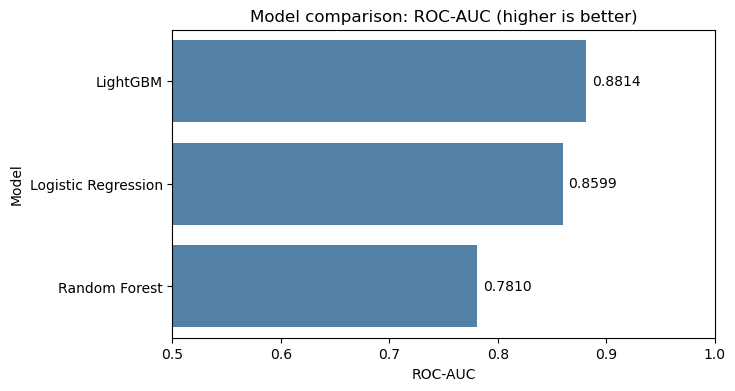

In [24]:
#Bar chart
plt.figure(figsize=(7, 4))
sns.barplot(x="ROC-AUC", y="Model", data=results, color="steelblue")
plt.xlim(0.5, 1)
plt.title("Model comparison: ROC-AUC (higher is better)")
for i, v in enumerate(results["ROC-AUC"]):
    plt.text(v + 0.005, i, f"{v:.4f}", va="center")
plt.show()

**Observation:** LightGBM has the highest ROC-AUC (0.8814), followed by Logistic Regression (0.8599) and Random Forest (0.7810).

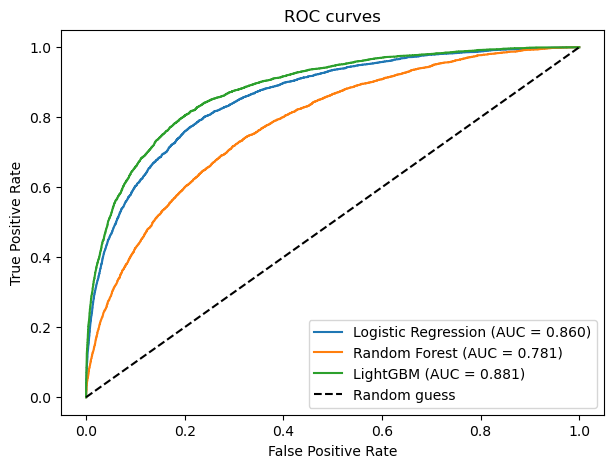

In [25]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 5))
for name, proba in [("Logistic Regression", lr_proba),
                    ("Random Forest", rf_proba),
                    ("LightGBM", lgbm_proba)]:
    fpr, tpr, _ = roc_curve(y_val, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_val, proba):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves")
plt.legend()
plt.show()

**Observation:**
- The LightGBM curve is the closest to the top-left corner, so it separates customers who will transact from those who will not better than the other models, at almost every threshold.
- Logistic Regression is close behind. Random Forest is clearly lower.
- All three curves are well above the random-guess line (AUC = 0.5), so every model learned useful patterns.

**Inference:** LightGBM is the best-performing model, and Random Forest is the weakest of the three.

## Step 5: Detailed Evaluation of the Best Model (LightGBM)
The confusion matrix shows how many customers the model classified correctly and incorrectly.

                    precision    recall  f1-score   support

No transaction (0)       0.97      0.84      0.90     35980
   Transaction (1)       0.35      0.75      0.48      4020

          accuracy                           0.83     40000
         macro avg       0.66      0.80      0.69     40000
      weighted avg       0.91      0.83      0.86     40000



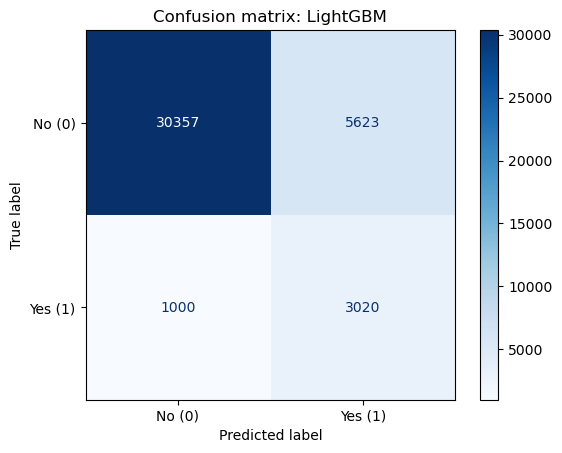

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

lgbm_pred = (lgbm_proba >= 0.5).astype(int)

print(classification_report(y_val, lgbm_pred,
                            target_names=["No transaction (0)", "Transaction (1)"]))

ConfusionMatrixDisplay(confusion_matrix(y_val, lgbm_pred),
                       display_labels=["No (0)", "Yes (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix: LightGBM")
plt.show()

**Observation:**

| | Predicted No (0) | Predicted Yes (1) |
|---|---|---|
| **Actually No (0)** | 30,357 | 5,623 |
| **Actually Yes (1)** | 1,000 | 3,020 |

- Of the 4,020 customers who will transact, LightGBM correctly found **3,020 (recall = 0.75)** and missed 1,000.
- Of the 8,643 customers it predicted as "will transact", **35% (precision = 0.35)** really will, which is about 3.5 times better than random targeting (about 10%).
- It also raised 5,623 false alarms (non-transactors predicted as transactors).
- Overall accuracy is 0.83, which is lower than the 0.8995 of the "always predict 0" baseline. This is expected: the model trades some accuracy to find many more real transactors (recall 0.75 instead of 0).

**Inference:** For the bank, missing a likely transactor is usually more costly than contacting a few extra customers, so the high recall of 0.75 is a good trade-off.

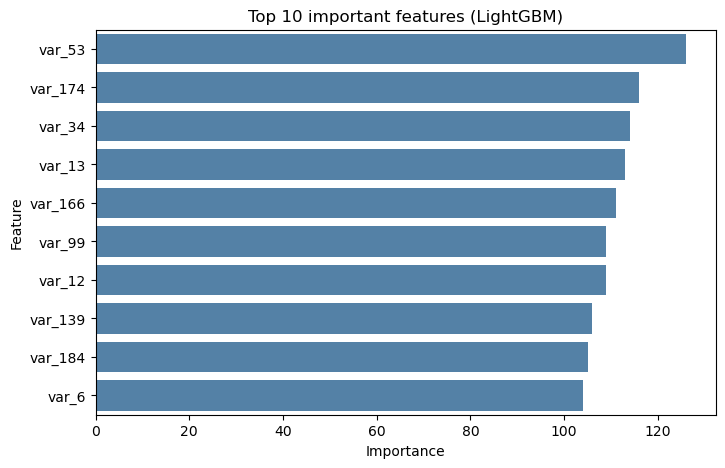

In [27]:
importance = pd.Series(lgbm.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=importance.head(10).values, y=importance.head(10).index, color="steelblue")
plt.title("Top 10 important features (LightGBM)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

**Observation:**
- The most used features are `var_53`, `var_174`, `var_34`, `var_13` and `var_166`. The bars are close in size (about 104 to 126), so no single feature dominates the model.
- Five features (`var_53`, `var_174`, `var_12`, `var_139`, `var_6`) also appear in the top 10 by correlation with the target, so both analyses point to similar features.

**Inference:** The prediction depends on many features working together, not one or two. Because the features are anonymized, I cannot name them in business terms, but the bank's data team could map these top features back to real fields.

# Model Comparison Report

Three models were trained on the same training data (160,000 rows) with class weights to handle the imbalance, and tested on the same validation data (40,000 rows).

| Model | ROC-AUC | Precision | Recall | F1 |
|---|---|---|---|---|
| **LightGBM** | **0.8814** | **0.3494** | 0.7512 | **0.4770** |
| Logistic Regression | 0.8599 | 0.2865 | 0.7754 | 0.4184 |
| Random Forest | 0.7810 | 0.3215 | 0.4271 | 0.3669 |

## Recommendation: LightGBM

I recommend **LightGBM** for production because:
1. **Best ROC-AUC (0.8814)**, so it ranks likely transactors above non-transactors better than the other models.
2. **Best precision and F1**, with recall of 0.75 (it finds 3,020 of the 4,020 customers who will transact).
3. **Handles the imbalance** well through the `is_unbalance` setting.
4. **Practical:** it is designed to train and predict quickly on large tabular data, needs no feature scaling, and is not sensitive to outliers.
5. **Beats the baseline:** a model that always predicts "no transaction" has 90% accuracy but 0 recall, while LightGBM finds 75% of real transactors.

## Why not the others?
- **Logistic Regression:** a strong baseline (ROC-AUC 0.8599), but it has lower precision and F1, and a linear model cannot capture complex patterns.
- **Random Forest:** the weakest (ROC-AUC 0.7810). It finds only 43% of the customers who will transact.

## Limitations and suggestions
- I used the default decision threshold of 0.5. The bank could choose a different threshold depending on the cost of a missed customer versus a wasted offer.
- Models were not heavily tuned, so hyperparameter tuning could improve the results further.
- In production, the model should be monitored and retrained regularly as customer behavior changes.

# Report on Challenges Faced

| # | Challenge | Technique used | Reason |
|---|---|---|---|
| 1 | **Imbalanced target** (about 90% class 0, 10% class 1) | `stratify` in the train/validation split, and `class_weight` / `is_unbalance` in the models | Both sets keep the same class ratio, and the model does not ignore the minority class |
| 2 | **Accuracy is misleading** (an "always 0" model gets 0.8995 accuracy with 0 recall) | Used ROC-AUC (main), Precision, Recall and F1 | These metrics show how well customers who will transact are actually found |
| 3 | **Features on different scales** (for example `var_5` std 7.86 vs `var_6` std 0.87) | `StandardScaler` for Logistic Regression | Linear models are sensitive to scale; tree-based models are not |
| 4 | **Data leakage risk** | Scaler fitted on training data only, then applied to validation data | Keeps the validation data unseen, so the results are honest |
| 5 | **Anonymized features** (no business meaning) | Statistical analysis, correlation and feature importance | Without domain knowledge, the data itself has to guide the analysis |
| 6 | **Weak signal** (highest correlation with target only 0.081; features almost independent) | Compared a linear model with tree-based models, and chose LightGBM | Tree-based boosting combines many weak signals better than a single linear model |
| 7 | **Outliers** | Checked with boxplots and kept them | They looked like natural variation, and tree-based models are not sensitive to them |

# Conclusion

- The dataset has 200,000 customers and 200 anonymized features. It is clean (no missing values) but **imbalanced** (about 10% class 1), and the signal is **weak and spread across many features**.
- I trained and compared three models using ROC-AUC, Precision, Recall and F1.
- **LightGBM** performed best (ROC-AUC = 0.8814, F1 = 0.4770), finding about 75% of the customers who will transact.

### How the bank can use this model
1. **Targeted marketing:** send offers to customers with a high predicted chance of transacting, to save campaign cost.
2. **Retention:** customers predicted not to transact can be targeted with re-engagement campaigns.
3. **Planning:** estimate overall customer activity to support business decisions.

### Future improvements
- Tune the model's hyperparameters and the decision threshold.
- Try techniques such as SMOTE or additional feature engineering.
- Retrain regularly with new data.